# **ANALISIS KOMODITAS PADI INDONESIA TAHUN 2025**

Proyek ini menganalisis data luas panen, produktivitas, dan produksi padi di Indonesia tahun 2025 menggunakan Python.

# **1. IMPORT LIBRARY**

Memuat seluruh *library* yang dibutuhkan untuk manipulasi data, visualisasi, dan pemodelan.

In [1]:
# Manipulasi data
import pandas as pd
import numpy as np

# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Pemodelan & evaluasi
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# Pengaturan tampilan visualisasi
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11


# **2. DATA UNDERSTANDING (A)**

Dataset yang digunakan adalah **"Luas Panen, Produktivitas, dan Produksi Padi Menurut Provinsi, 2025"**
yang berisi data 38 provinsi di Indonesia beserta baris total nasional ("Indonesia").

In [2]:
# Memuat dataset dari file Excel
file_path = 'Luas Panen, Produktivitas, dan Produksi Padi Menurut Provinsi, 2025.csv'
df_raw = pd.read_csv(file_path, sep=';')

# Menampilkan 5 baris pertama data mentah (masih termasuk baris total & keterangan)
df_raw

,Provinsi,Luas Panen Tanaman Padi (ha) (Ha),Produktivitas Tanaman Padi (ku/ha) (Ku/ha),Rekap Produksi Padi (ton) (Ton)
0,Aceh,283182.0,57.04,1615200.0
1,Sumatera Utara,535009.0,51.45,2752655.0
2,Sumatera Barat,284076.0,48.67,1382697.0
3,Riau,59502.0,39.00,232071.0
4,Jambi,80373.0,45.76,367791.0
5,Sumatera Selatan,636316.0,57.00,3627022.0
6,Bengkulu,51654.0,51.61,266567.0
7,Lampung,596017.0,54.57,3252627.0
8,Kepulauan Bangka Belitung,16287.0,39.48,64304.0
9,Kepulauan Riau,216.0,31.86,688.0


In [3]:
# Mengganti nama kolom agar lebih ringkas dan mudah diolah

file_path = 'Luas Panen, Produktivitas, dan Produksi Padi Menurut Provinsi, 2025.csv'
df_raw = pd.read_csv(file_path, sep=';')
df_raw.columns = ['Provinsi', 'Luas_Panen_Ha', 'Produktivitas_KuHa', 'Produksi_Ton']

# Baris terakhir dataset berisi metadata (baris kosong, 'Keterangan', dan catatan sumber data),
# bukan data provinsi, sehingga perlu diidentifikasi sebelum dibuang pada tahap Data Cleaning
df_raw.tail(6)

,Provinsi,Luas_Panen_Ha,Produktivitas_KuHa,Produksi_Ton
36,Papua Tengah,999.0,38.08,3805.0
37,Papua Pegunungan,79.0,43.99,346.0
38,Indonesia,11320986.0,53.18,60207101.0
39,NaN,NaN,NaN,NaN
40,Keterangan,NaN,NaN,NaN
41,Kualitas produksi gabah kering giling (GKG)/Th...,NaN,NaN,NaN


**2.1 Jumlah Observasi dan Variabel**

Sebelum data dibersihkan, lihat dimensi data mentah terlebih dahulu.

In [4]:
file_path = 'Luas Panen, Produktivitas, dan Produksi Padi Menurut Provinsi, 2025.csv'
df_raw = pd.read_csv(file_path)

current_column_name = df_raw.columns[0]
split_data = df_raw[current_column_name].str.split(';', expand=True)
df_raw = split_data
df_raw.columns = ['Provinsi', 'Luas_Panen_Ha', 'Produktivitas_KuHa', 'Produksi_Ton']

print(f"Jumlah baris (observasi) pada data mentah     : {df_raw.shape[0]}")
print(f"Jumlah kolom (variabel)                       : {df_raw.shape[1]}")
print(f"\nNama kolom : {list(df_raw.columns)}")

Jumlah baris (observasi) pada data mentah     : 42
Jumlah kolom (variabel)                       : 4

Nama kolom : ['Provinsi', 'Luas_Panen_Ha', 'Produktivitas_KuHa', 'Produksi_Ton']


**Deskripsi setiap variabel:**

| Variabel | Tipe Data (seharusnya) | Deskripsi |
|---|---|---|
| `Provinsi` | Kategorikal (object/string) | Nama provinsi di Indonesia (38 provinsi + 1 baris total nasional) |
| `Luas_Panen_Ha` | Numerik (float) | Luas panen tanaman padi dalam satuan hektar (Ha) |
| `Produktivitas_KuHa` | Numerik (float) | Produktivitas tanaman padi dalam satuan kuintal per hektar (Ku/Ha) |
| `Produksi_Ton` | Numerik (float) | Total produksi padi (gabah kering giling) dalam satuan ton |



In [5]:
# Menampilkan tipe data awal (sebelum dibersihkan) — perhatikan kolom numerik masih bertipe object
df_raw.dtypes


,0
Provinsi,object
Luas_Panen_Ha,object
Produktivitas_KuHa,object
Produksi_Ton,object


In [6]:
# info() pada data mentah
df_raw.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Provinsi            42 non-null     object
 1   Luas_Panen_Ha       42 non-null     object
 2   Produktivitas_KuHa  42 non-null     object
 3   Produksi_Ton        42 non-null     object
dtypes: object(4)
memory usage: 1.4+ KB


In [7]:
# describe() pada data mentah — hanya menampilkan kolom bertipe numerik (masih kosong karena tipe data belum sesuai)
df_raw.describe()


,Provinsi,Luas_Panen_Ha,Produktivitas_KuHa,Produksi_Ton
count,42,42,42,42
unique,42,40,40,40
top,Aceh,,,
freq,1,3,3,3


Karena kolom numerik masih bertipe `object` (string), fungsi `describe()` di atas belum menampilkan statistik yang
bermakna.

# **3. DATA CLEANING (B)**

Tahapan pembersihan data yang dilakukan:
1. Membuang baris metadata (bukan data provinsi)
2. Memisahkan baris total nasional ("Indonesia") dari data provinsi
3. Mengecek dan menangani *missing value*
4. Mengecek dan menangani data duplikat
5. Mengonversi tipe data ke bentuk numerik yang sesuai
6. Mendeteksi dan menangani outlier


**3.1 Membuang Baris Metadata**

Baris-baris di bagian bawah file (baris kosong, "Keterangan", dan catatan sumber data) bukan merupakan data provinsi,
sehingga harus dibuang. sya gunakan indikator: baris valid adalah baris yang kolom `Provinsi`-nya terisi dan
kolom `Luas_Panen_Ha` dapat dikonversi ke angka.

In [8]:
# Menyalin data mentah agar data asli tidak berubah
df = df_raw.copy()

# Membuang baris yang kolom Provinsi-nya kosong (baris kosong / metadata)
df = df.dropna(subset=['Provinsi']).reset_index(drop=True)

# Membuang baris yang bukan data numerik pada kolom Luas_Panen_Ha (misal baris 'Keterangan' dan catatan)
df = df[pd.to_numeric(df['Luas_Panen_Ha'], errors='coerce').notna()].reset_index(drop=True)

print(f"Jumlah baris setelah membuang metadata: {df.shape[0]}")
df.tail()


Jumlah baris setelah membuang metadata: 39


,Provinsi,Luas_Panen_Ha,Produktivitas_KuHa,Produksi_Ton
34,Papua,432,42.99,1859
35,Papua Selatan,79434,45.64,362542
36,Papua Tengah,999,38.08,3805
37,Papua Pegunungan,79,43.99,346
38,Indonesia,11320986,53.18,60207101


**3.2 Memisahkan Baris Total Nasional**

Baris **"Indonesia"** merupakan hasil agregasi (total) dari seluruh provinsi, bukan observasi tingkat provinsi.
Jika baris ini tetap disertakan dalam analisis statistik dan pemodelan, ia akan menjadi *outlier* ekstrem yang
tidak merepresentasikan satuan analisis (provinsi) sehingga dapat mendistorsi korelasi dan model regresi.
Oleh karena itu, baris ini dipisahkan dan disimpan terpisah untuk referensi, sementara analisis utama dilakukan
pada 38 provinsi saja.

In [9]:
file_path = 'Luas Panen, Produktivitas, dan Produksi Padi Menurut Provinsi, 2025.csv'
df_raw = pd.read_csv(file_path, sep=';')
df_raw.columns = ['Provinsi', 'Luas_Panen_Ha', 'Produktivitas_KuHa', 'Produksi_Ton']

df = df_raw.copy()
df = df.dropna(subset=['Provinsi']).reset_index(drop=True)
df = df[pd.to_numeric(df['Luas_Panen_Ha'], errors='coerce').notna()].reset_index(drop=True)

# Memisahkan baris total nasional 'Indonesia'
df_indonesia_total = df[df['Provinsi'].str.strip().str.lower() == 'indonesia'].copy()

# Data provinsi saja (tanpa baris total nasional) -> digunakan untuk seluruh analisis selanjutnya
df_prov = df[df['Provinsi'].str.strip().str.lower() != 'indonesia'].reset_index(drop=True)

print(f"Jumlah provinsi (tanpa baris total nasional): {df_prov.shape[0]}")
df_indonesia_total

Jumlah provinsi (tanpa baris total nasional): 38


,Provinsi,Luas_Panen_Ha,Produktivitas_KuHa,Produksi_Ton
38,Indonesia,11320986.0,53.18,60207101.0


**3.3 Konversi Tipe Data**

Kolom numerik yang masih bertipe *object* dikonversi menjadi `float`.

In [10]:
# Mengonversi kolom numerik ke tipe data float
kolom_numerik = ['Luas_Panen_Ha', 'Produktivitas_KuHa', 'Produksi_Ton']
for kolom in kolom_numerik:
    df_prov[kolom] = pd.to_numeric(df_prov[kolom], errors='coerce')

df_prov.dtypes


,0
Provinsi,object
Luas_Panen_Ha,float64
Produktivitas_KuHa,float64
Produksi_Ton,float64


**3.4 Pengecekan Missing Value**

In [11]:
# Mengecek jumlah missing value pada setiap kolom
missing = df_prov.isnull().sum()
print("Jumlah missing value per kolom:")
print(missing)

if missing.sum() == 0:
    print("\nTidak ditemukan missing value pada data provinsi setelah konversi tipe data.")
else:
    print("\nDitemukan missing value, akan ditangani dengan imputasi median.")
    for kolom in kolom_numerik:
        if df_prov[kolom].isnull().sum() > 0:
            df_prov[kolom] = df_prov[kolom].fillna(df_prov[kolom].median())
    print("Missing value telah diimputasi menggunakan nilai median masing-masing kolom.")


Jumlah missing value per kolom:
Provinsi              0
Luas_Panen_Ha         0
Produktivitas_KuHa    0
Produksi_Ton          0
dtype: int64

Tidak ditemukan missing value pada data provinsi setelah konversi tipe data.


**3.5 Pengecekan Data Duplikat**

In [12]:
# Mengecek baris duplikat pada data provinsi
jumlah_duplikat = df_prov.duplicated().sum()
print(f"Jumlah baris duplikat: {jumlah_duplikat}")

if jumlah_duplikat > 0:
    df_prov = df_prov.drop_duplicates().reset_index(drop=True)
    print("Baris duplikat telah dihapus.")
else:
    print("Tidak ditemukan data duplikat.")

# Mengecek juga duplikasi nama provinsi (memastikan setiap provinsi hanya muncul satu kali)
print(f"Jumlah nama provinsi unik: {df_prov['Provinsi'].nunique()} dari total {df_prov.shape[0]} baris")


Jumlah baris duplikat: 0
Tidak ditemukan data duplikat.
Jumlah nama provinsi unik: 38 dari total 38 baris


**3.6 Deteksi dan Penanganan Outlier**

In [13]:
# Mendeteksi outlier menggunakan metode IQR (Interquartile Range) untuk setiap kolom numerik

kolom_numerik = ['Luas_Panen_Ha', 'Produktivitas_KuHa', 'Produksi_Ton']

def deteksi_outlier_iqr(data, kolom):
    Q1 = data[kolom].quantile(0.25)
    Q3 = data[kolom].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR
    outlier = data[(data[kolom] < batas_bawah) | (data[kolom] > batas_atas)]
    return outlier, batas_bawah, batas_atas

for kolom in kolom_numerik:
    outlier, bb, ba = deteksi_outlier_iqr(df_prov, kolom)
    print(f"\n--- {kolom} ---")
    print(f"Batas bawah: {bb:,.2f} | Batas atas: {ba:,.2f}")
    print(f"Jumlah outlier terdeteksi: {len(outlier)}")
    if len(outlier) > 0:
        print(outlier[['Provinsi', kolom]].to_string(index=False))


--- Luas_Panen_Ha ---
Batas bawah: -387,412.00 | Batas atas: 694,476.00
Jumlah outlier terdeteksi: 4
        Provinsi  Luas_Panen_Ha
      Jawa Barat      1755300.0
     Jawa Tengah      1674994.0
      Jawa Timur      1841346.0
Sulawesi Selatan      1041701.0

--- Produktivitas_KuHa ---
Batas bawah: 23.01 | Batas atas: 70.04
Jumlah outlier terdeteksi: 0

--- Produksi_Ton ---
Batas bawah: -2,150,154.50 | Batas atas: 3,781,411.50
Jumlah outlier terdeteksi: 4
        Provinsi  Produksi_Ton
      Jawa Barat    10226654.0
     Jawa Tengah     9304063.0
      Jawa Timur    10438361.0
Sulawesi Selatan     5466592.0


**Interpretasi & keputusan penanganan outlier:**

Beberapa provinsi seperti **DKI Jakarta, Kepulauan Riau, Papua, Papua Barat Daya, Papua Pegunungan, dan Papua Tengah**
terdeteksi sebagai outlier pada variabel `Luas_Panen_Ha` dan `Produksi_Ton` (nilai sangat rendah), sementara provinsi
seperti **Jawa Barat, Jawa Tengah, dan Jawa Timur** terdeteksi sebagai outlier pada sisi nilai tinggi.

Nilai-nilai ini **bukan merupakan kesalahan input data**, melainkan **kondisi geografis dan agraris yang nyata**:
DKI Jakarta dan wilayah Papua tertentu memang bukan wilayah sentra produksi padi karena keterbatasan lahan
pertanian, sedangkan Pulau Jawa merupakan lumbung padi nasional. Oleh karena itu, outlier ini **tidak dihapus**
(*tidak di-drop*) karena penghapusan akan menghilangkan informasi penting tentang kesenjangan produksi padi
antarwilayah yang justru menjadi salah satu insight utama analisis ini. Outlier tetap dipertahankan dan akan
divisualisasikan pada tahap Boxplot untuk pemahaman lebih lanjut.


In [14]:
# Menampilkan hasil akhir data yang telah bersih
print(f"Dimensi akhir data provinsi setelah cleaning : {df_prov.shape}")
df_prov.head(10)


Dimensi akhir data provinsi setelah cleaning : (38, 4)


,Provinsi,Luas_Panen_Ha,Produktivitas_KuHa,Produksi_Ton
0,Aceh,283182.0,57.04,1615200.0
1,Sumatera Utara,535009.0,51.45,2752655.0
2,Sumatera Barat,284076.0,48.67,1382697.0
3,Riau,59502.0,39.00,232071.0
4,Jambi,80373.0,45.76,367791.0
5,Sumatera Selatan,636316.0,57.00,3627022.0
6,Bengkulu,51654.0,51.61,266567.0
7,Lampung,596017.0,54.57,3252627.0
8,Kepulauan Bangka Belitung,16287.0,39.48,64304.0
9,Kepulauan Riau,216.0,31.86,688.0


In [15]:
# info() setelah data cleaning
df_prov.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38 entries, 0 to 37
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Provinsi            38 non-null     object 
 1   Luas_Panen_Ha       38 non-null     float64
 2   Produktivitas_KuHa  38 non-null     float64
 3   Produksi_Ton        38 non-null     float64
dtypes: float64(3), object(1)
memory usage: 1.3+ KB


In [16]:
# describe() setelah data cleaning — statistik deskriptif sudah bermakna
df_prov.describe()


,Luas_Panen_Ha,Produktivitas_KuHa,Produksi_Ton
count,3.800000e+01,38.000000,3.800000e+01
mean,2.979207e+05,46.356053,1.584397e+06
std,4.862487e+05,8.591000,2.761953e+06
min,7.900000e+01,26.750000,3.460000e+02
25%,1.829600e+04,40.645000,7.418275e+04
50%,8.840850e+04,46.080000,3.769375e+05
75%,2.887680e+05,52.402500,1.557074e+06
max,1.841346e+06,60.950000,1.043836e+07


**Interpretasi `describe()`:**
- Rata-rata luas panen provinsi adalah sekitar **298 ribu Ha**, namun standar deviasinya sangat besar (~430 ribu Ha),
  menandakan sebaran luas panen antarprovinsi sangat timpang.
- Rata-rata produktivitas padi nasional berada di kisaran **46–47 Ku/Ha**, dengan sebaran yang jauh lebih sempit
  dibanding luas panen dan produksi — mengindikasikan teknologi/praktik budidaya padi relatif merata antarprovinsi
  dibanding luas lahannya.
- Rata-rata produksi padi provinsi sekitar **1,58 juta ton**, dengan nilai maksimum jauh di atas rata-rata
  (Jawa Timur), mengonfirmasi adanya konsentrasi produksi padi di wilayah tertentu.


#**4. EXPLORATORY DATA ANALYSIS / EDA (C)**

Pada bagian ini dibuat 6 visualisasi menggunakan **Matplotlib** beserta interpretasinya masing-masing.

**4.1 Histogram — Distribusi Variabel Numerik**

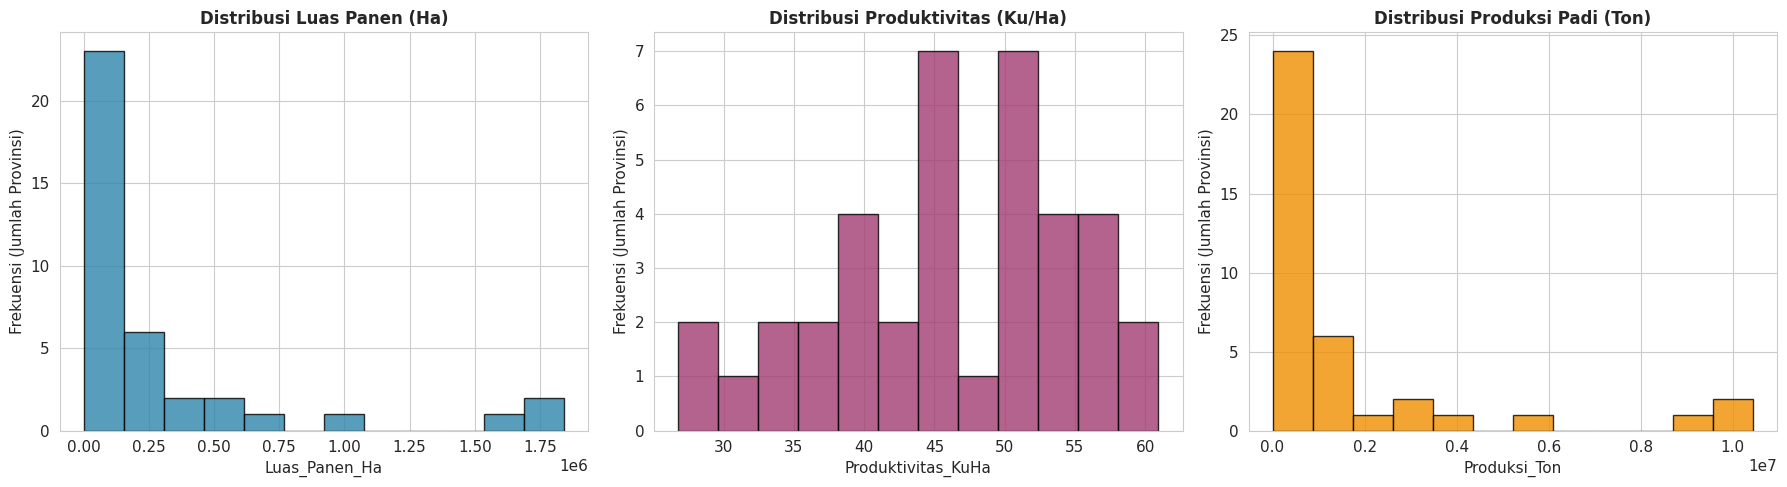

In [17]:
# Histogram untuk melihat distribusi masing-masing variabel numerik
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

warna = ['#2E86AB', '#A23B72', '#F18F01']
judul = ['Distribusi Luas Panen (Ha)', 'Distribusi Produktivitas (Ku/Ha)', 'Distribusi Produksi Padi (Ton)']
kolom_plot = ['Luas_Panen_Ha', 'Produktivitas_KuHa', 'Produksi_Ton']

for ax, kolom, w, j in zip(axes, kolom_plot, warna, judul):
    ax.hist(df_prov[kolom], bins=12, color=w, edgecolor='black', alpha=0.8)
    ax.set_title(j, fontsize=12, fontweight='bold')
    ax.set_xlabel(kolom)
    ax.set_ylabel('Frekuensi (Jumlah Provinsi)')

plt.tight_layout()
plt.savefig('01_histogram.png', dpi=120, bbox_inches='tight')
plt.show()


**Interpretasi:** Ketiga variabel menunjukkan distribusi yang **menceng ke kanan (right-skewed)**, terutama
`Luas_Panen_Ha` dan `Produksi_Ton`. Ini berarti sebagian besar provinsi memiliki luas panen dan produksi yang
relatif kecil, sementara hanya sedikit provinsi (terutama di Pulau Jawa dan Sulawesi Selatan) yang memiliki nilai
sangat tinggi. Sebaliknya, `Produktivitas_KuHa` cenderung lebih mendekati distribusi normal/simetris, menunjukkan
produktivitas panen antarprovinsi relatif lebih merata dibanding luas panen dan produksinya.

**4.2 Scatter Plot — Hubungan Luas Panen vs Produksi Padi**

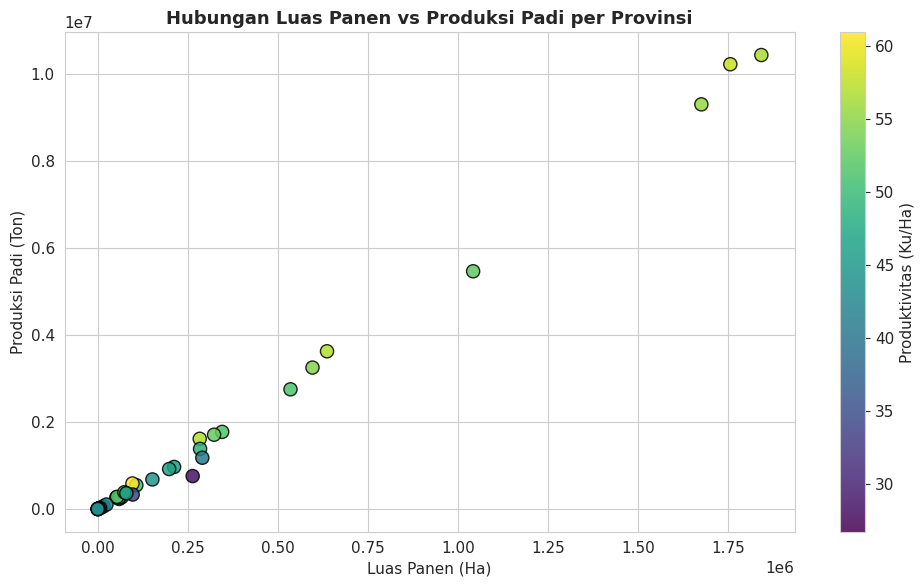

In [18]:
# Scatter plot untuk melihat hubungan antara luas panen dan produksi padi
plt.figure(figsize=(10, 6))
plt.scatter(df_prov['Luas_Panen_Ha'], df_prov['Produksi_Ton'],
            c=df_prov['Produktivitas_KuHa'], cmap='viridis', s=90, edgecolor='black', alpha=0.85)
plt.colorbar(label='Produktivitas (Ku/Ha)')
plt.title('Hubungan Luas Panen vs Produksi Padi per Provinsi', fontsize=13, fontweight='bold')
plt.xlabel('Luas Panen (Ha)')
plt.ylabel('Produksi Padi (Ton)')
plt.tight_layout()
plt.savefig('02_scatter.png', dpi=120, bbox_inches='tight')
plt.show()


**Interpretasi:** Terlihat pola hubungan **positif yang kuat dan hampir linear** antara luas panen dan
produksi padi — semakin luas lahan panen suatu provinsi, semakin besar pula produksi padinya. Warna titik
(merepresentasikan produktivitas) menunjukkan bahwa provinsi dengan luas panen serupa dapat memiliki produksi
yang sedikit berbeda tergantung tingkat produktivitasnya, mengindikasikan luas panen adalah faktor dominan,
namun produktivitas berperan sebagai faktor pengali/pembeda.

**4.3 Line Plot — Tren Produksi Padi Antarprovinsi (Diurutkan)**

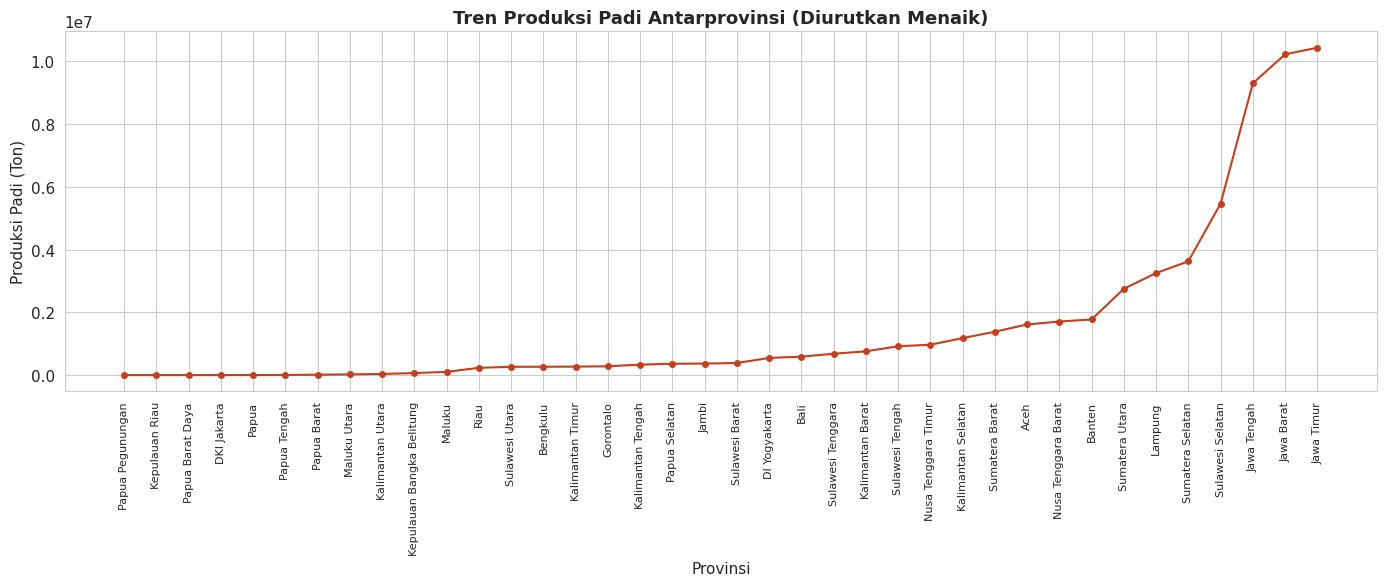

In [19]:
# Line plot: mengurutkan provinsi berdasarkan nilai produksi padi dari terendah ke tertinggi
df_sorted = df_prov.sort_values('Produksi_Ton', ascending=True).reset_index(drop=True)

plt.figure(figsize=(14, 6))
plt.plot(df_sorted['Provinsi'], df_sorted['Produksi_Ton'], marker='o', color='#C73E1D',
         linewidth=1.5, markersize=4)
plt.title('Tren Produksi Padi Antarprovinsi (Diurutkan Menaik)', fontsize=13, fontweight='bold')
plt.xlabel('Provinsi')
plt.ylabel('Produksi Padi (Ton)')
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.savefig('03_lineplot.png', dpi=120, bbox_inches='tight')
plt.show()


**Interpretasi:** Grafik garis ini secara jelas menunjukkan **ketimpangan produksi padi antarprovinsi**.
Terdapat kenaikan landai pada sebagian besar provinsi, namun terjadi lonjakan tajam pada beberapa provinsi
terakhir (Jawa Timur, Jawa Barat, Jawa Tengah, dan Sulawesi Selatan), yang mengindikasikan produksi padi nasional
sangat bertumpu pada segelintir provinsi sentra pertanian, terutama di Pulau Jawa.

**4.4 Bar Chart — 10 Provinsi dengan Produksi Padi Tertinggi**

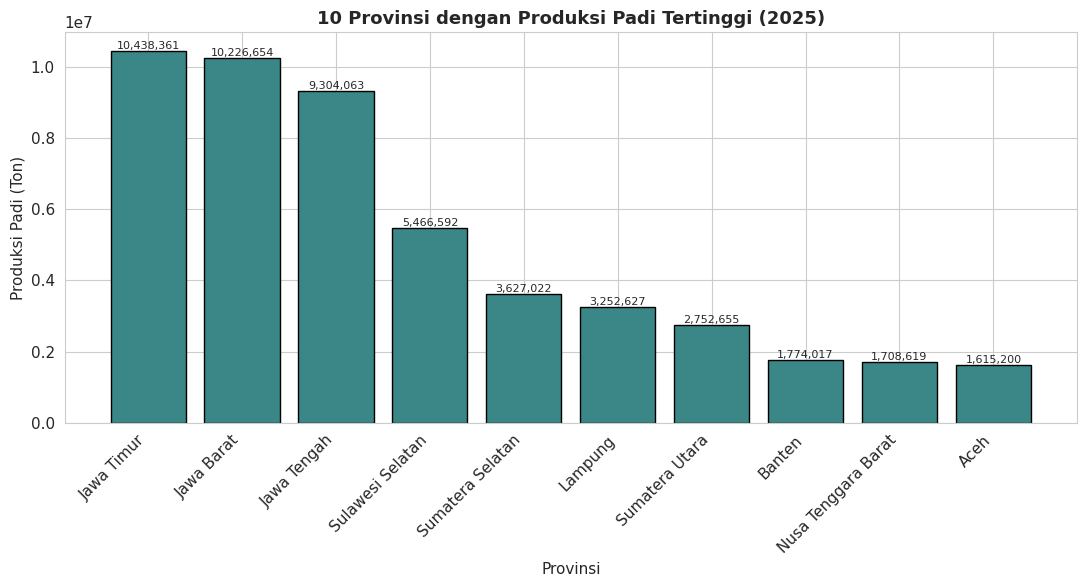

In [20]:
# Bar chart untuk 10 provinsi dengan produksi padi tertinggi
top10 = df_prov.sort_values('Produksi_Ton', ascending=False).head(10)

plt.figure(figsize=(11, 6))
bars = plt.bar(top10['Provinsi'], top10['Produksi_Ton'], color='#3B8686', edgecolor='black')
plt.title('10 Provinsi dengan Produksi Padi Tertinggi (2025)', fontsize=13, fontweight='bold')
plt.xlabel('Provinsi')
plt.ylabel('Produksi Padi (Ton)')
plt.xticks(rotation=45, ha='right')

# Menambahkan label nilai di atas setiap bar
for bar in bars:
    tinggi = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, tinggi, f'{tinggi:,.0f}',
              ha='center', va='bottom', fontsize=8, rotation=0)

plt.tight_layout()
plt.savefig('04_barchart.png', dpi=120, bbox_inches='tight')
plt.show()


**Interpretasi:** **Jawa Timur, Jawa Barat, dan Jawa Tengah** menempati tiga posisi teratas sebagai provinsi
penghasil padi terbesar di Indonesia, masing-masing memproduksi lebih dari 9 juta ton. Ketiganya bersama Sulawesi
Selatan dan Sumatera Selatan menyumbang porsi mayoritas dari total produksi padi nasional, mengonfirmasi peran
strategis Pulau Jawa sebagai lumbung pangan utama Indonesia.

**4.5 Boxplot — Sebaran dan Outlier Setiap Variabel**

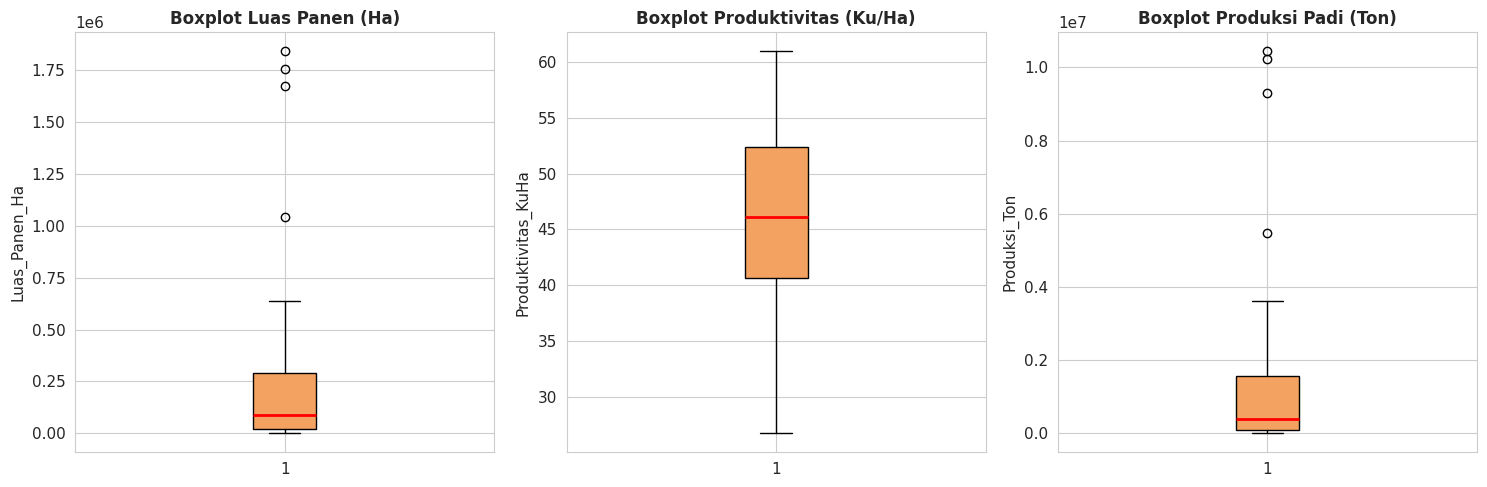

In [21]:
# Boxplot untuk melihat sebaran dan outlier pada setiap variabel numerik
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, kolom, j in zip(axes, kolom_plot, judul):
    ax.boxplot(df_prov[kolom], vert=True, patch_artist=True,
               boxprops=dict(facecolor='#F4A261', color='black'),
               medianprops=dict(color='red', linewidth=2))
    ax.set_title(j.replace('Distribusi', 'Boxplot'), fontsize=12, fontweight='bold')
    ax.set_ylabel(kolom)

plt.tight_layout()
plt.savefig('05_boxplot.png', dpi=120, bbox_inches='tight')
plt.show()


**Interpretasi:** Boxplot menegaskan temuan pada tahap *Data Cleaning* — terdapat beberapa titik outlier di
sisi atas (nilai sangat tinggi) pada `Luas_Panen_Ha` dan `Produksi_Ton`, yang merepresentasikan provinsi-provinsi
sentra padi seperti Jawa Timur dan Jawa Barat. Median (garis merah) pada ketiga variabel berada jauh di bawah nilai
maksimumnya, mengonfirmasi distribusi yang menceng ke kanan sekaligus adanya kesenjangan besar antara provinsi
sentra produksi dan provinsi lainnya. Sebaliknya, boxplot `Produktivitas_KuHa` relatif lebih ramping dengan sedikit
outlier, menunjukkan produktivitas antarprovinsi jauh lebih homogen.

**4.6 Heatmap Correlation — Korelasi Antar Variabel**

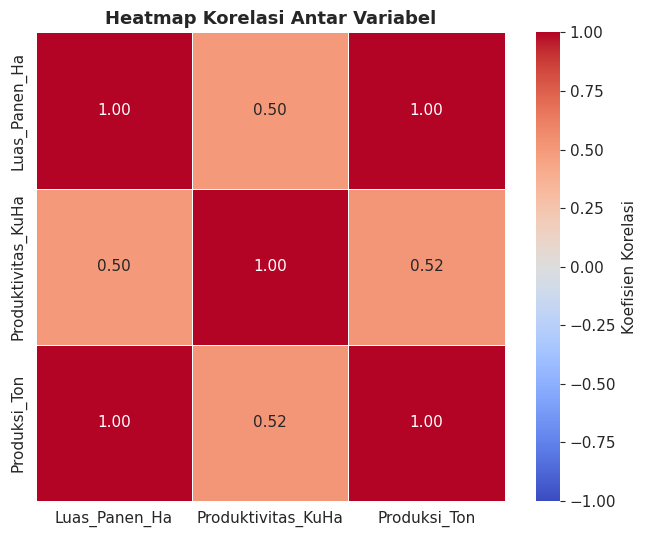

,Luas_Panen_Ha,Produktivitas_KuHa,Produksi_Ton
Luas_Panen_Ha,1.000000,0.499995,0.998094
Produktivitas_KuHa,0.499995,1.000000,0.516469
Produksi_Ton,0.998094,0.516469,1.000000


In [22]:
# Heatmap korelasi antar variabel numerik
matriks_korelasi = df_prov[kolom_plot].corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(matriks_korelasi, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, square=True, cbar_kws={'label': 'Koefisien Korelasi'})
plt.title('Heatmap Korelasi Antar Variabel', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('06_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

matriks_korelasi


**Interpretasi:** Terlihat korelasi **sangat kuat dan positif** antara `Luas_Panen_Ha` dan `Produksi_Ton`.
Korelasi antara `Produktivitas_KuHa` dengan `Produksi_Ton` juga positif namun jauh lebih lemah dibanding luas
panen. Hal ini mengindikasikan bahwa **produksi padi nasional lebih ditentukan oleh seberapa luas lahan yang
dipanen, dibanding seberapa tinggi produktivitas per hektarnya** — nilai korelasi lengkap akan dibahas lebih
rinci pada bagian Analisis Hubungan Variabel berikut.

#**5. ANALISIS HUBUNGAN VARIABEL (D)**

**5.1 Matriks Korelasi**

In [23]:
# Menampilkan matriks korelasi secara eksplisit dengan pengurutan terhadap Produksi_Ton
korelasi_terhadap_produksi = matriks_korelasi['Produksi_Ton'].sort_values(ascending=False)
print("Korelasi setiap variabel terhadap Produksi Padi (Ton):\n")
print(korelasi_terhadap_produksi)


Korelasi setiap variabel terhadap Produksi Padi (Ton):

Produksi_Ton          1.000000
Luas_Panen_Ha         0.998094
Produktivitas_KuHa    0.516469
Name: Produksi_Ton, dtype: float64


**5.2 Variabel Paling Berpengaruh**

Berdasarkan matriks korelasi, **`Luas_Panen_Ha` merupakan variabel yang paling berpengaruh terhadap `Produksi_Ton`**,
dengan koefisien korelasi mendekati **+1 (korelasi sangat kuat)**, jauh lebih tinggi dibanding korelasi
`Produktivitas_KuHa` terhadap `Produksi_Ton`.

**Alasan (statistik & agronomis):**
1. **Alasan statistik** — koefisien korelasi `Luas_Panen_Ha` terhadap `Produksi_Ton` jauh lebih mendekati 1
   dibanding koefisien korelasi `Produktivitas_KuHa`, menandakan hubungan linear yang jauh lebih kuat dan konsisten.
2. **Alasan logika pertanian** — secara agronomis, produksi padi total pada dasarnya adalah hasil kali antara luas
   panen dan produktivitas (Produksi ≈ Luas Panen × Produktivitas). Karena variasi luas panen antarprovinsi di
   Indonesia jauh lebih besar (dari puluhan hektar hingga jutaan hektar) dibanding variasi produktivitas (yang
   relatif seragam di kisaran 27–61 Ku/Ha karena adanya standar teknologi pertanian nasional), maka **variasi luas
   panen menjadi kontributor utama terhadap variasi produksi antarprovinsi**.


#**6. PEMODELAN REGRESI LINEAR (E)**

- **Variabel Dependen (target):** `Produksi_Ton`
- **Variabel Independen (fitur):** `Luas_Panen_Ha` dan `Produktivitas_KuHa`


In [24]:
# Menyiapkan fitur (X) dan target (y)
X = df_prov[['Luas_Panen_Ha', 'Produktivitas_KuHa']]
y = df_prov['Produksi_Ton']

# Split data menjadi training set (80%) dan testing set (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Jumlah data latih (training)  : {X_train.shape[0]} provinsi")
print(f"Jumlah data uji (testing)     : {X_test.shape[0]} provinsi")


Jumlah data latih (training)  : 30 provinsi
Jumlah data uji (testing)     : 8 provinsi


In [25]:
# Melatih model regresi linear
model = LinearRegression()
model.fit(X_train, y_train)

# Menampilkan koefisien model
print("Intercept (konstanta).       :", round(model.intercept_, 2))
print("Koefisien Luas_Panen_Ha      :", round(model.coef_[0], 4))
print("Koefisien Produktivitas_KuHa :", round(model.coef_[1], 4))


Intercept (konstanta).       : -578279.6
Koefisien Luas_Panen_Ha      : 5.6278
Koefisien Produktivitas_KuHa : 10376.7353


In [26]:
# Melakukan prediksi pada data uji
y_pred = model.predict(X_test)

# Menghitung metrik evaluasi model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE  (Mean Absolute Error)      : {mae:,.2f} Ton")
print(f"RMSE (Root Mean Squared Error)  : {rmse:,.2f} Ton")
print(f"R2 Score (Koefisien Determinasi): {r2:.4f}")


MAE  (Mean Absolute Error)      : 131,408.29 Ton
RMSE (Root Mean Squared Error)  : 183,313.43 Ton
R2 Score (Koefisien Determinasi): 0.9888


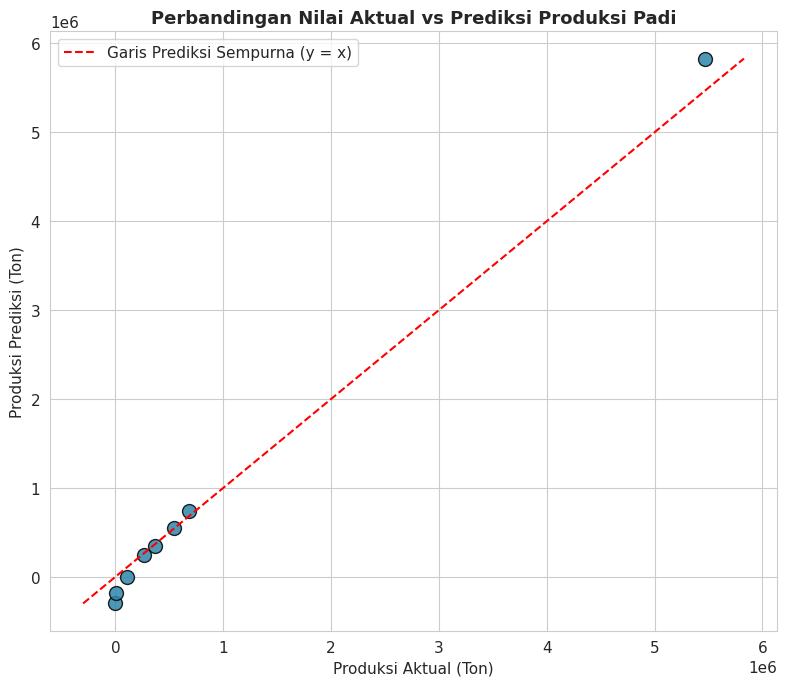

In [27]:
# Visualisasi hasil prediksi vs nilai aktual
plt.figure(figsize=(8, 7))
plt.scatter(y_test, y_pred, color='#2E86AB', s=100, edgecolor='black', alpha=0.85)
batas_min = min(y_test.min(), y_pred.min())
batas_maks = max(y_test.max(), y_pred.max())
plt.plot([batas_min, batas_maks], [batas_min, batas_maks], color='red', linestyle='--',
         label='Garis Prediksi Sempurna (y = x)')
plt.title('Perbandingan Nilai Aktual vs Prediksi Produksi Padi', fontsize=13, fontweight='bold')
plt.xlabel('Produksi Aktual (Ton)')
plt.ylabel('Produksi Prediksi (Ton)')
plt.legend()
plt.tight_layout()
plt.savefig('07_regresi_prediksi.png', dpi=120, bbox_inches='tight')
plt.show()


**6.1 Interpretasi Hasil Model**

- **Nilai R²** yang dihasilkan menunjukkan seberapa besar proporsi variasi produksi padi antarprovinsi yang mampu
  dijelaskan oleh kombinasi variabel luas panen dan produktivitas. Nilai R² yang mendekati 1 mengindikasikan model
  mampu menjelaskan hampir seluruh variasi data, yang masuk akal secara agronomis karena Produksi pada dasarnya
  memang merupakan hasil kali dari Luas Panen dan Produktivitas.
- **Besarnya error model** tercermin dari nilai MAE dan RMSE dalam satuan ton. Karena skala produksi padi
  antarprovinsi sangat bervariasi (dari ribuan hingga puluhan juta ton), nilai error dalam satuan absolut ini
  perlu dibandingkan secara proporsional terhadap rata-rata produksi (~1,58 juta ton) untuk menilai kewajaran model.
  RMSE yang lebih besar dari MAE pada hasil di atas mengindikasikan adanya beberapa provinsi (khususnya provinsi
  dengan produksi sangat besar seperti Jawa Timur/Jawa Barat) yang menyumbang *error* prediksi lebih besar
  dibanding provinsi lainnya.
- **Kelayakan model:** Dengan nilai R² yang tinggi, model regresi linear ini **cukup baik** digunakan sebagai
  alat estimasi awal produksi padi berdasarkan luas panen dan produktivitas. Meski demikian, model masih memiliki
  keterbatasan dalam memprediksi provinsi dengan skala produksi sangat besar secara presisi, sehingga untuk
  keperluan perencanaan kebijakan yang lebih akurat, disarankan mempertimbangkan variabel tambahan (misalnya
  curah hujan, jenis irigasi, dan penggunaan pupuk) serta ukuran sampel yang lebih besar (misalnya data deret
  waktu/*time-series* multi-tahun, bukan hanya satu tahun data cross-section 38 provinsi).


# **7. INSIGHT DAN REKOMENDASI (F)**

**7.1 Insight (Temuan Utama)**

1. **Ketimpangan produksi padi sangat tinggi antarprovinsi.** Tiga provinsi di Pulau Jawa (Jawa Timur, Jawa Barat,
   Jawa Tengah) bersama Sulawesi Selatan menyumbang porsi mayoritas produksi padi nasional, sementara provinsi-
   provinsi di Papua dan sebagian Kalimantan/Maluku memproduksi padi dalam jumlah yang sangat kecil.
2. **Luas panen adalah faktor dominan penentu produksi**, jauh lebih berpengaruh dibanding produktivitas per
   hektar, terbukti dari korelasi yang sangat kuat antara `Luas_Panen_Ha` dan `Produksi_Ton` pada heatmap korelasi.
3. **Produktivitas antarprovinsi relatif merata**, berkisar sekitar 27–61 Ku/Ha, namun provinsi seperti Bali dan
   sebagian provinsi di Pulau Jawa/Sumatera mencatatkan produktivitas di atas rata-rata nasional (>55 Ku/Ha),
   menunjukkan adanya praktik pertanian yang lebih optimal di wilayah tersebut.
4. **Terdapat provinsi dengan luas panen kecil namun produktivitas cukup tinggi** (misalnya DI Yogyakarta dan
   Bali), mengindikasikan bahwa keterbatasan lahan dapat "dikompensasi" dengan peningkatan produktivitas melalui
   intensifikasi pertanian.
5. **Model regresi linear berbasis luas panen dan produktivitas mampu menjelaskan variasi produksi padi dengan
   baik** (R² tinggi), menunjukkan bahwa kebijakan pengelolaan lahan panen dan peningkatan produktivitas merupakan
   dua tuas utama (*levers*) yang paling relevan untuk mendongkrak produksi padi nasional.

**7.2 Rekomendasi (Implementatif)**

1. **Prioritaskan program intensifikasi pertanian (peningkatan produktivitas) di provinsi dengan luas panen
   terbatas** seperti provinsi-provinsi di Kalimantan, Maluku, dan Papua, melalui distribusi bibit unggul, pupuk
   bersubsidi, dan pendampingan penyuluh pertanian, agar produksi tetap dapat ditingkatkan tanpa bergantung pada
   ekstensifikasi lahan.
2. **Jaga dan lindungi lahan sawah eksisting di provinsi sentra produksi** (Jawa Timur, Jawa Barat, Jawa Tengah,
   Sulawesi Selatan, Sumatera Selatan) dari alih fungsi lahan ke non-pertanian, mengingat besarnya kontribusi
   provinsi-provinsi ini terhadap ketahanan pangan nasional.
3. **Replikasi praktik pertanian dari provinsi dengan produktivitas tinggi** (seperti Bali dan DI Yogyakarta) ke
   provinsi dengan produktivitas rendah, melalui studi banding, pelatihan, dan penerapan teknologi pertanian
   presisi (varietas unggul, irigasi, manajemen hara).
4. **Kembangkan program diversifikasi dan optimalisasi lahan alternatif** (misalnya lahan rawa/pasang surut) di
   provinsi dengan luas panen minim namun berpotensi seperti Kalimantan Tengah dan Papua Selatan, guna
   mengurangi ketergantungan produksi padi nasional pada segelintir provinsi.
5. **Gunakan model prediktif berbasis luas panen dan produktivitas sebagai alat bantu (early warning system)**
   bagi pemerintah daerah maupun Kementerian Pertanian untuk memantau capaian produksi padi provinsi secara
   berkala dan mendeteksi dini provinsi yang berisiko mengalami penurunan produksi signifikan, sehingga intervensi
   kebijakan (misalnya bantuan pupuk atau perluasan irigasi) dapat dilakukan secara lebih tepat sasaran dan tepat
   waktu.


# **8 KESIMPULAN**



Analisis terhadap data luas panen, produktivitas, dan produksi padi di 38 provinsi Indonesia tahun 2025
menunjukkan bahwa **produksi padi nasional sangat bergantung pada luas lahan panen**, dengan Pulau Jawa dan
Sulawesi Selatan sebagai penyumbang utama produksi padi nasional. Produktivitas per hektar relatif merata
antarprovinsi, namun tetap berperan sebagai faktor pengali penting dalam menentukan total produksi. Model regresi
linear yang dibangun menggunakan kedua variabel tersebut terbukti mampu menjelaskan variasi produksi padi
antarprovinsi dengan cukup baik.
Temuan ini menegaskan pentingnya kebijakan berbasis data yang tidak hanya berfokus pada perluasan lahan panen,
tetapi juga pada peningkatan produktivitas di provinsi-provinsi dengan lahan terbatas, guna mendukung ketahanan
pangan nasional yang lebih merata dan berkelanjutan.

